# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

In [53]:
print(
    "Answer (Problem 1): The file contains 41,188 contact records from bank"
    "telemarketing campaigns run between May 2008 and November 2010"
    
)

Answer (Problem 1): The file contains 41,188 contact records from banktelemarketing campaigns run between May 2008 and November 2010


### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [61]:
df = pd.read_csv('bank-additional-full.csv', sep = ';')
print("Shape",df.shape)

Shape (41188, 21)


In [59]:
import pandas as pd
import time
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [60]:
pd.set_option("display.max_columns",None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9,5)

In [6]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [62]:
print("Total null values:", df.isnull().sum().sum())
unknown_counts = {
    col: (df[col] == "unknown").sum()
    for col in df.select_dtypes(include="object").columns
          if col!="y"
}
print("Rows labeled 'unknown' (no literal Nans; treat as missing category):")
pd.Series(unknown_counts).sort_values(ascending=False)

Total null values: 0
Rows labeled 'unknown' (no literal Nans; treat as missing category):


C:\Users\dvb\AppData\Local\Temp\ipykernel_8772\4257532844.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns


default        8597
education      1731
housing         990
loan            990
job             330
marital          80
contact           0
month             0
day_of_week       0
poutcome          0
dtype: int64

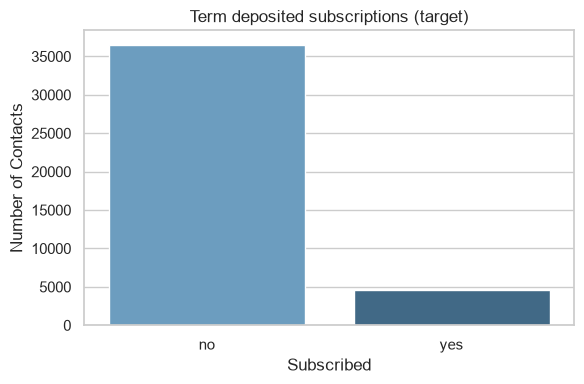

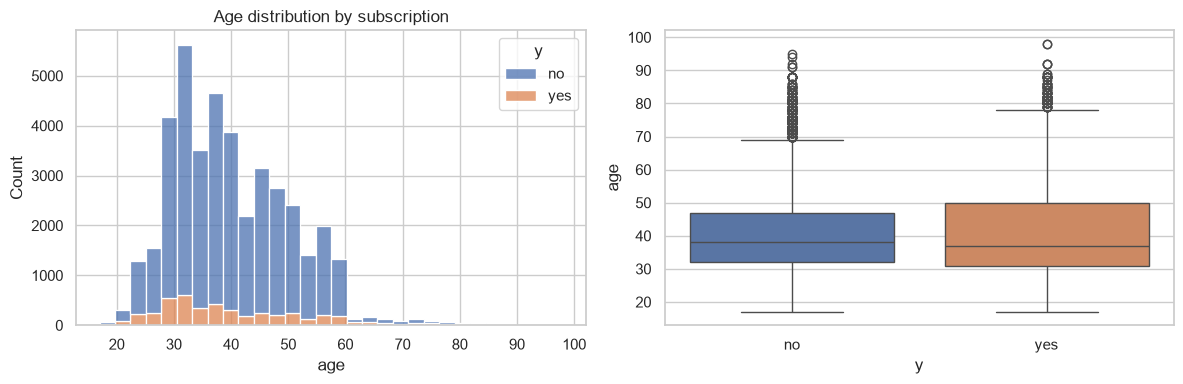

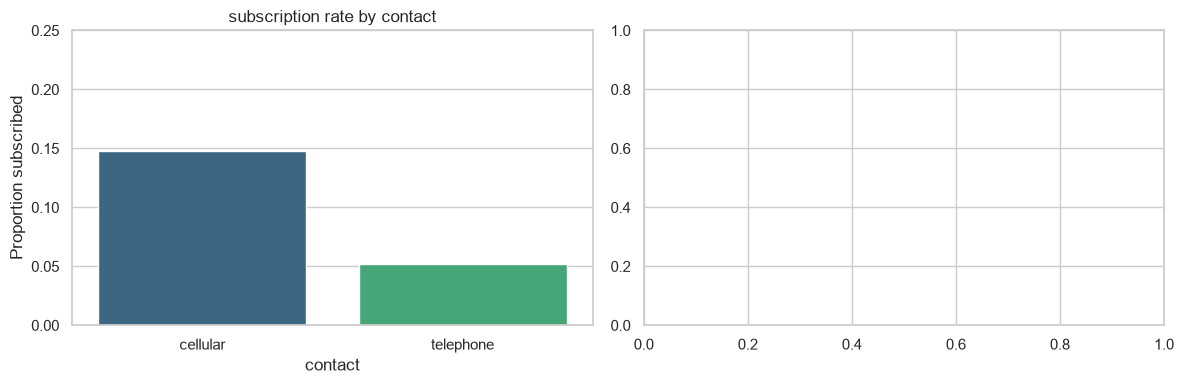

<Figure size 900x500 with 0 Axes>

In [72]:
# Exploratory Analysis and Visualization
fig,ax = plt.subplots(figsize=(6,4))
yes_counts = df["y"].value_counts()
sns.barplot(x=yes_counts.index, y=yes_counts.values, hue=yes_counts.index, legend=False, ax=ax, palette="Blues_d")
ax.set_title("Term deposited subscriptions (target)")
ax.set_xlabel("Subscribed")
ax.set_ylabel("Number of Contacts")
plt.tight_layout()
plt.show()

# Continous: age vs outcome
fig, axes = plt.subplots(1,2, figsize=(12,4))
sns.histplot(data=df, x="age", hue="y", multiple="stack", bins=30, ax=axes[0])
axes[0].set_title("Age distribution by subscription")
sns.boxplot(data=df, x="y", y="age", hue="y", legend=False, ax=axes[1])
ax.set_title("Age by Outcome")
ax.set_xlabel("Subscribed")
plt.tight_layout()
plt.show()

# Categorical: Subsciption rate by contact channel and month
df_eda=df.copy()
df_eda["subscribed"] = (df_eda["y"] == "yes").astype(int)
by_contact = df_eda.groupby("contact", as_index=False)["subscribed"].mean()
by_month = df_eda.groupby("month", as_index=False)["subscribed"].mean().sort_values("subscribed",ascending=False)

fig,axes = plt.subplots(1,2, figsize=(12,4))
sns.barplot(data=by_contact,x="contact", y="subscribed", hue="contact", legend=False, ax=axes[0], palette="viridis")
axes[0].set_title("subscription rate by contact")
axes[0].set_ylabel("Proportion subscribed")
axes[0].set_ylim(0,0.25)
plt.tight_layout()
plt.show()

sns.barplot(data=by_month,x="month", y="subscribed", hue="month", legend=False, ax=axes[1], palette="crest")
axes[0].set_title("subscription rate by month of contact")
axes[0].set_ylabel("Proportion subscribed")
axes[0].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [12]:
business_objective = (
    "Predict whether a client will subscribe to a term deposit before or"
    "without placing a call, so the blank can prioritze outbound contacts,"
    "reduce wasted call time, and improve campaign ROI"
)
print(business_objective)

Predict whether a client will subscribe to a term deposit before orwithout placing a call, so the blank can prioritze outbound contacts,reduce wasted call time, and improve campaign ROI


### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [15]:
BANK_FEATURE_COLS = [
    "age","job","marital","education","default","housing","loan",
    "contact","month","day_of_week","campaign","pdays","previous","poutcome"
]
X = df[BANK_FEATURE_COLS].copy()
y=(df["y"]=="yes").astype(int)

In [20]:
numeric_features=["age","campaign","pdays","previous"]
categorical_features=[c for c in BANK_FEATURE_COLS if c not in numeric_features]

preprocessor = ColumnTransformer(
    transformers = [
        ("num", StandardScaler(), numeric_features),
        ("cat",OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)
X_prep = preprocessor.fit_transform(X)
feature_names=preprocessor.get_feature_names_out()
X_model = pd.DataFrame(X_prep, columns=feature_names)
print("Prepared features", X_model.shape)
y.value_counts(normalize=True)

Prepared features (41188, 57)


y
0    0.887346
1    0.112654
Name: proportion, dtype: float64

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [22]:
X_train, X_test,y_train,y_test = train_test_split(
    X_model, y, test_size=0.2, random_state=42, stratify=y
)
print("Train size:", len(X_train), "Test size:", len(X_test))

Train size: 32950 Test size: 8238


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [23]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train,y_train)
baseline_test = dummy.score(X_test, y_test)
print(f"Baseline test accuracy (majority class): {baseline_test:4f}")



Baseline test accuracy (majority class): 0.887351


In [26]:
print(
    f"Models should improve recall/F1 for 'yes' - only ~{(y.mean() * 100): 1f}% subscribe."
)

Models should improve recall/F1 for 'yes' - only ~ 11.265417% subscribe.


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [27]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

### Problem 9: Score the Model

What is the accuracy of your model?

In [28]:
print("Train accuracy", log_reg.score(X_train, y_train))
print("Test accuracy", log_reg.score(X_test, y_test))

Train accuracy 0.8971168437025797
Test accuracy 0.898154891964069


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [44]:
def evaluate_classifier(name, estimator, X_tr, y_tr,X_te,y_te):
    start = time.perf_counter()
    fit_X, fit_y = X_tr, y_tr
    if name == "SVM" and len(y_tr) > 8_000:
        fit_X, _, fit_y, _=train_test_split(
        X_tr, y_tr, train_size=8_000, random_state=42, stratify=y_tr
    )
    estimator.fit(fit_X, fit_y)
    train_time = time.perf_counter() - start
    return{
        "Model":name,
        "Train Time (s)": round(train_time,3),
        "Train Accuracy": round(estimator.score(X_tr, y_tr),4),
        "Train Accuracy": round(estimator.score(X_tr, y_tr),4)
}

In [46]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(random_state=42)
}

# Create comparison DataFrame by evaluating each classifier
comparison_df = pd.DataFrame(
    [evaluate_classifier(n, c, X_train, y_train, X_test, y_test) for n, c in models.items()]
)

comparison_df

,Model,Train Time (s),Train Accuracy
0,Logistic Regression,0.136,0.8971
1,KNN,0.019,0.9073
2,Decision Tree,0.423,0.9933
3,SVM,2.930,0.8991


### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [52]:
X_tune, _, y_tune, _ = train_test_split(
    X_train,y_train,train_size=10_000, random_state=42, stratify=y_train
)
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    param_grid={"max_depth":[5,10,20,None], "min_samples_leaf":[1,5,20]},
    scoring="f1",
    cv=3
)
dt_grid.fit(X_tune, y_tune)
best_dt = dt_grid.best_estimator_
best_dt.fit(X_train, y_train)
y_pred = best_dt.predict(X_test)
print("Best params:", dt_grid.best_params_)

Best params: {'max_depth': 10, 'min_samples_leaf': 5}


##### Questions